# Análise geral das carteiras offshore com pandas

Este notebook usa os mesmos dados do sistema: os 53 arquivos da Pershing e do UBS de setembro/2026,
ingeridos pelo pipeline. A partir deles, montamos tabelas com pandas para responder perguntas de gestão:

1. Como está distribuído o patrimônio (classe, moeda, custodiante)?
2. Quanto cada carteira rendeu e quanto oscilou?
3. Qual foi a pior queda do mês (drawdown)?
4. Quais ativos puxaram o resultado?
5. Quanto a carteira depende do euro?

As funções usadas estão em `app/analytics.py`, as mesmas que alimentam a rota `/analytics/overview` e a tela **Análise geral**.

> Os clientes e os preços são fictícios. O foco é o método.

In [1]:
import logging
import sys
from dataclasses import replace
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent))  # permite importar o pacote app
logging.disable(logging.WARNING)

from app import analytics as an
from app.config import Settings
from app.container import Container

pd.set_option("display.float_format", "{:,.4f}".format)
pd.set_option("display.width", 140)

# Sobe o sistema em memória e ingere os arquivos de exemplo (mesmo caminho do worker).
c = Container(replace(Settings.from_env(), database_url=None, use_aws=False, load_samples=True))
clientes = list(c.reference.clients)
print(f"{len(c.repository.file_records())} arquivos ingeridos para {clientes}")

53 arquivos ingeridos para ['maria', 'manoel']


## 1. Das posições dos custodiantes para um DataFrame

Cada linha é um ativo num arquivo de um custodiante. Ainda não está consolidado: é o dado bruto, já traduzido pelos adapters.

In [2]:
posicoes = an.holdings_frame(c.repository, c.reference, clientes)
print(posicoes.shape)
posicoes.head()

(198, 11)


,client_id,custodian,file_date,security_id,name,label,asset_class,currency,quantity,price,price_factor
0,maria,Pershing,2026-08-31,US0378331005,Apple Inc.,AAPL,renda_variavel,USD,100.0000,220.4000,1.0000
1,maria,Pershing,2026-08-31,US9229083632,Vanguard S&P 500 ETF,VOO,renda_variavel,USD,20.0000,521.5400,1.0000
2,maria,Pershing,2026-08-31,CASH:USD,Caixa em dólar,Caixa em dólar,caixa,USD,922.8000,1.0000,1.0000
3,maria,Pershing,2026-09-01,US0378331005,Apple Inc.,AAPL,renda_variavel,USD,100.0000,221.2500,1.0000
4,maria,Pershing,2026-09-01,US9229083632,Vanguard S&P 500 ETF,VOO,renda_variavel,USD,20.0000,527.4200,1.0000


## 2. Painel diário consolidado

`merge_asof` pega, para cada dia, o arquivo mais recente de cada custodiante (se um custodiante atrasar um dia, vale o último arquivo dele).
Depois, cada posição é valorizada em dólar: quantidade × preço × câmbio (renda fixa cotada em %).

In [3]:
painel = an.daily_panel(posicoes, c.reference)
patrimonio = painel.pivot_table(index="day", columns="client_id", values="value_usd", aggfunc="sum")
patrimonio.tail()

client_id,manoel,maria
day,,
2026-09-24,"146,156.9000","113,889.5800"
2026-09-25,"145,912.2000","114,458.3580"
2026-09-28,"145,987.3000","114,066.4100"
2026-09-29,"145,925.8000","114,340.7250"
2026-09-30,"146,000.0000","113,994.2500"


## 3. Alocação em 30/09

`pivot_table` cruza cliente × classe de ativo. `normalize` transforma em percentual da carteira de cada cliente.

In [4]:
fim = painel[painel["day"] == painel["day"].max()]
por_classe = fim.pivot_table(
    index="asset_class", columns="client_id", values="value_usd", aggfunc="sum"
).fillna(0)
por_classe_pct = por_classe / por_classe.sum()
por_moeda_pct = pd.crosstab(
    fim["currency"], fim["client_id"], values=fim["value_usd"], aggfunc="sum", normalize="columns"
).fillna(0)
display(por_classe_pct.style.format("{:.1%}"))
display(por_moeda_pct.style.format("{:.1%}"))

client_id,manoel,maria
asset_class,,
caixa,4.3%,7.4%
renda_fixa,78.5%,48.2%
renda_variavel,17.2%,44.4%


client_id,manoel,maria
currency,,
EUR,0.0%,51.3%
USD,100.0%,48.7%


## 4. Retorno diário descontando depósitos e saques

Mesma convenção do domínio: o dinheiro do cliente entra no início do dia.

`retorno = valor_hoje / (valor_ontem + fluxo_hoje) − 1`

In [5]:
fluxos = an.flows_frame(c.repository, c.reference, clientes)
diario = an.daily_returns(painel, fluxos)
retornos = diario.pivot(index="day", columns="client_id", values="ret").dropna()
retornos.describe()

client_id,manoel,maria
count,21.0000,21.0000
mean,0.0003,0.0013
std,0.0017,0.0048
min,-0.0027,-0.0076
25%,-0.0012,-0.0024
50%,0.0005,0.0024
75%,0.0016,0.0033
max,0.0031,0.0103


## 5. Métricas de risco e retorno

- **TWR**: retornos diários encadeados, `(1 + r).prod() − 1`
- **Volatilidade anualizada**: desvio padrão diário × √252
- **Drawdown**: queda a partir do maior valor já atingido, `crescimento / crescimento.cummax() − 1`
- **Sharpe**: retorno anualizado acima da taxa livre de risco, dividido pela volatilidade

Com só 21 dias úteis, as métricas anualizadas são ilustrativas.

In [6]:
metricas = pd.DataFrame({cid: an.risk_metrics(retornos[cid]) for cid in clientes}).T
metricas[["twr", "volatility_annual", "max_drawdown", "sharpe", "best_day", "worst_day", "positive_days"]]

,twr,volatility_annual,max_drawdown,sharpe,best_day,worst_day,positive_days
maria,0.0264,0.0754,-0.0076,3.5913,2026-09-24 00:00:00,2026-09-23 00:00:00,13
manoel,0.0062,0.0274,-0.0043,1.0601,2026-09-21 00:00:00,2026-09-23 00:00:00,12


In [7]:
# Conferência: o TWR do pandas bate com o TWR oficial do domínio (Decimal)?
from app.services import PortfolioService

oficial = PortfolioService(c.repository, c.reference)
pd.DataFrame(
    {
        "pandas": metricas["twr"].astype(float),
        "domínio (Decimal)": [
            float(oficial.performance(cid, date(2026, 8, 31), date(2026, 9, 30)).twr) for cid in clientes
        ],
    },
    index=clientes,
).assign(diferença=lambda d: d["pandas"] - d["domínio (Decimal)"]).style.format(
    {"pandas": "{:.6%}", "domínio (Decimal)": "{:.6%}", "diferença": "{:.1e}"}
)

,pandas,domínio (Decimal),diferença
maria,2.641842%,2.641843%,-6.8e-09
manoel,0.615507%,0.615507%,2.2e-16


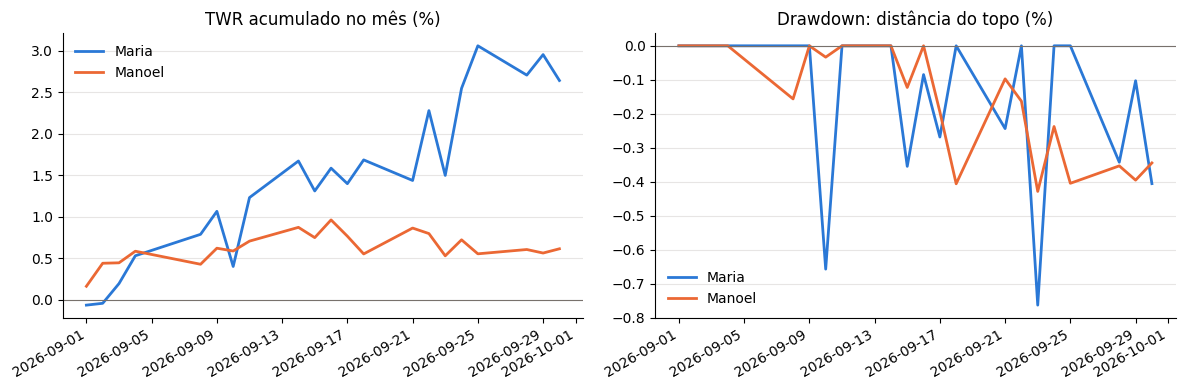

In [8]:
cores = {"maria": "#2a78d6", "manoel": "#eb6834"}
crescimento = (1 + retornos).cumprod()
drawdown = crescimento / crescimento.cummax() - 1

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
for cid in clientes:
    ax1.plot(crescimento.index, (crescimento[cid] - 1) * 100, color=cores[cid], lw=2, label=cid.title())
    ax2.plot(drawdown.index, drawdown[cid] * 100, color=cores[cid], lw=2, label=cid.title())
ax1.set_title("TWR acumulado no mês (%)")
ax2.set_title("Drawdown: distância do topo (%)")
for ax in (ax1, ax2):
    ax.axhline(0, color="#78716c", lw=0.8)
    ax.grid(axis="y", color="#e7e5e4")
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False)
fig.autofmt_xdate()
plt.tight_layout()

## 6. De onde veio o resultado: contribuição por ativo

`contribuição = Σ peso do ativo ontem × retorno do ativo hoje`

O retorno do ativo vem do preço em dólar, então compras e vendas não aparecem como ganho.
A linha "Outros efeitos" junta dividendos, taxas e juros compostos, e fecha exatamente o TWR.

In [9]:
for cid in clientes:
    tabela = an.contributions(painel, diario, cid)
    tabela["contribution"] = tabela["contribution"] * 100
    print(f"\n{cid.title()}  (TWR {metricas.loc[cid, 'twr']:.2%})")
    print(
        tabela.rename(columns={"label": "ativo", "contribution": "contribuição (p.p.)"}).to_string(
            index=False, float_format="{:+.3f}".format
        )
    )


Maria  (TWR 2.64%)
                            ativo  contribuição (p.p.)
                             AAPL               +1.350
                              VOO               +0.857
Título corporativo EUR 3,25% 2029               +0.411
                    Caixa em euro               -0.006
                   Outros efeitos               +0.030

Manoel  (TWR 0.62%)
                         ativo  contribuição (p.p.)
                          MSFT               +0.529
        T-Note EUA 4,125% 2030               +0.072
Título corporativo USD 5% 2028               -0.004
                Outros efeitos               +0.019


## 7. Concentração

HHI = soma dos pesos ao quadrado. `1 / HHI` é o **número efetivo de ativos**: quantos ativos de mesmo peso dariam a mesma diversificação.

In [10]:
pd.DataFrame({cid: an.concentration(fim[fim["client_id"] == cid]) for cid in clientes}).T

,top_position,top_weight,hhi,effective_positions,positions
maria,"Título corporativo EUR 3,25% 2029",0.4817,0.3342,2.9919,5
manoel,"T-Note EUA 4,125% 2030",0.6115,0.4354,2.2969,4


## 8. Cenário de câmbio: e se o euro variar?

Só a Maria tem ativos em euro. Aplicamos choques de −20% a +20% sobre a parte em euro da carteira dela.

In [11]:
maria = fim[fim["client_id"] == "maria"]
em_euro = maria.loc[maria["currency"] == "EUR", "value_usd"].sum()
total = maria["value_usd"].sum()
choques = pd.Series([-0.20, -0.10, -0.05, 0.05, 0.10, 0.20], name="variação do euro")
cenario = pd.DataFrame(
    {
        "impacto (US$)": choques * em_euro,
        "impacto na carteira": choques * em_euro / total,
    },
    index=choques.map("{:+.0%}".format),
)
print(f"Parte da Maria em euro: US$ {em_euro:,.2f} ({em_euro / total:.1%} da carteira)")
cenario.style.format({"impacto (US$)": "{:+,.2f}", "impacto na carteira": "{:+.2%}"})

Parte da Maria em euro: US$ 58,481.75 (51.3% da carteira)


,impacto (US$),impacto na carteira
variação do euro,,
-20%,+nan,+nan%
-10%,+nan,+nan%
-5%,+nan,+nan%
+5%,+nan,+nan%
+10%,+nan,+nan%
+20%,+nan,+nan%


## 9. Correlação entre os ativos

`pct_change` dá o retorno diário de cada ativo; `.corr()` mostra quais se movem juntos.
Com preços sintéticos, os números aqui são aleatórios; com dados reais, esta tabela ajuda a ver se a diversificação é de verdade.

In [12]:
precos = painel.pivot_table(index="day", columns="label", values="unit_price_usd", aggfunc="mean")
retorno_ativos = precos.pct_change(fill_method=None).iloc[1:]
retorno_ativos = retorno_ativos.loc[:, retorno_ativos.std() > 0]  # caixa em dólar não varia
retorno_ativos.corr().style.format("{:.2f}").background_gradient(cmap="RdBu_r", vmin=-1, vmax=1)

label,AAPL,Caixa em euro,MSFT,"T-Note EUA 4,125% 2030","Título corporativo EUR 3,25% 2029",Título corporativo USD 5% 2028,VOO
label,,,,,,,
AAPL,1.00,0.31,0.09,0.04,0.24,-0.32,0.41
Caixa em euro,0.31,1.00,-0.09,-0.18,0.84,0.13,-0.30
MSFT,0.09,-0.09,1.00,-0.15,0.04,-0.34,0.19
"T-Note EUA 4,125% 2030",0.04,-0.18,-0.15,1.00,0.10,-0.28,0.04
"Título corporativo EUR 3,25% 2029",0.24,0.84,0.04,0.10,1.00,0.01,-0.49
Título corporativo USD 5% 2028,-0.32,0.13,-0.34,-0.28,0.01,1.00,-0.15
VOO,0.41,-0.30,0.19,0.04,-0.49,-0.15,1.00


## Conclusões

- **Maria** rendeu mais no mês, com mais oscilação. Quase metade da carteira está num único título em euro, o que deixa **metade do patrimônio exposta ao câmbio**: uma queda de 10% do euro custaria cerca de 5% da carteira.
- **Manoel** tem perfil conservador e oscilou pouco. A concentração dele é maior (o T-Note passa de 60% da carteira), mas é um título do Tesouro americano, de baixo risco.
- O **pior dia da Maria (23/09)** é efeito de dado, não de mercado: é a correção das 2 cotas de VOO que a Pershing informou a mais em 22/09. É exatamente a quebra de reconciliação que continua aberta no backoffice, e mostra por que reconciliar importa.
- O TWR calculado com pandas bate com o do domínio (Decimal) até a sétima casa decimal. A diferença vem do arredondamento em centavos que o domínio faz em cada posição.